# ICT-4202 | Artificial Intelligence and Machine Learning Laboratory
## Final Laboratory Examination — Set 08
**Islamic University, Kushtia, Bangladesh**  
Department of Information and Communication Technology

> **Notebook purpose:** Question-matched solutions with brief background theory, mathematical notation, readable Python, reproducible output, interpretation, and viva revision. This is a learning/reporting notebook, not a claim of official model answers.

| Question | Topic | Marks |
|:--|:--|--:|
| Q1 | DLS/IDDFS root-visit tracing | 25 |
| Q2 | WEKA IBk preprocessing and J48 | 30 |
| Q3 | Train/test regression on chosen data | 35 |
| Q4 | Viva: cutoff, CV, scaling, regression, R² | 10 |

**Execution:** Open in JupyterLab/VS Code, choose a Python kernel, then use **Run All**. All random experiments use a fixed seed. Markdown cells use MathJax (`$...$` and `$$...$$`) to render equations on GitHub/Jupyter.

**Quick access - one file per numbered question:** [Q1 / A](Set_08_A.py) | [Q2 / B](Set_08_B.py) | [Q3 / C](Set_08_C.py) | [Q4 / D: Viva practice](Set_08_D.py).

Q1-Q3 contain the required practical work (including all subparts). Q4 is a viva, so its `.py` file is a revision/self-quiz tool, not an extra algorithm assignment. This notebook contains solutions, explanations, mathematical theory, and the Q4 viva questions.

---
## Q1. DLS and IDDFS (25 marks)
**Question specification**  
`A→{B,C}, B→{D,E}, C→{F}, D→{H}, E→{I}, F→{G}`. Run DLS with depths 2 and 3, then IDDFS to G, display each iteration trace and count visits to root A.

### Theory and mathematical background
**Depth-Limited Search (DLS)** stops descending beyond an allowed depth $\ell$. A depth cutoff means the search might succeed with a larger limit; *failure* means no answer was found without such a cutoff.

**Iterative Deepening DFS (IDDFS)** performs DLS repeatedly at limits $0,1,2,\ldots$ until a goal is found:
$$IDDFS(\ell)=DLS(0),DLS(1),\dots,DLS(\ell).$$
It revisits shallow nodes, trading some repeated time for the memory efficiency of depth-first search. In a tree, DLS is commonly characterized by $O(b^\ell)$ time and $O(b\ell)$ space when sibling iterators are retained; IDDFS has roughly $O(b^d)$ time and $O(bd)$ space for a finite branching factor.

In [1]:
def depth_limited_search(graph, start, goal, limit):
    """Return path, status (success/cutoff/failure), expanded sequence."""
    expanded = []
    def visit(node, path, depth):
        expanded.append((node, depth))
        if node == goal: return path, 'success'
        if depth >= limit:
            eligible = [v for v in graph.get(node, []) if v not in path]
            return None, ('cutoff' if eligible else 'failure')
        had_cutoff = False
        for nxt in graph.get(node, []):
            if nxt in path: continue
            result, status = visit(nxt, path + [nxt], depth + 1)
            if status == 'success': return result, status
            if status == 'cutoff': had_cutoff = True
        return None, 'cutoff' if had_cutoff else 'failure'
    path, status = visit(start, [start], 0)
    return path, status, expanded

def iddfs(graph, start, goal, max_depth=10):
    iterations = []
    for limit in range(max_depth+1):
        path, status, expanded = depth_limited_search(graph, start, goal, limit)
        iterations.append((limit, path, status, expanded))
        if status == 'success': break
        if status == 'failure': break
    return path, iterations

def print_iddfs(graph, start, goal, max_depth=10):
    path, iterations = iddfs(graph, start, goal, max_depth)
    for limit, candidate, status, expanded in iterations:
        trace = ' -> '.join(node for node, depth in expanded)
        print(f'Limit={limit} | status={status:7} | expanded={trace} | path={candidate}')
    print(f'IDDFS path: {path}; root visits: {len(iterations)}')
    return path, iterations

graph={'A':['B','C'],'B':['D','E'],'C':['F'],
       'D':['H'],'E':['I'],'F':['G'],'G':[],'H':[],'I':[]}
for limit in [2,3]:
    path,status,expanded=depth_limited_search(graph,'A','G',limit)
    print(f'DLS(limit={limit}): status={status}; path={path}; trace={expanded}')
path,iterations=print_iddfs(graph,'A','G',8)
root_visits=sum(node=='A' for limit,p,status,tr in iterations for node,depth in tr)
print('Direct count of root visits across DLS iterations:',root_visits)
assert path==['A','C','F','G']


DLS(limit=2): status=cutoff; path=None; trace=[('A', 0), ('B', 1), ('D', 2), ('E', 2), ('C', 1), ('F', 2)]
DLS(limit=3): status=success; path=['A', 'C', 'F', 'G']; trace=[('A', 0), ('B', 1), ('D', 2), ('H', 3), ('E', 2), ('I', 3), ('C', 1), ('F', 2), ('G', 3)]
Limit=0 | status=cutoff  | expanded=A | path=None
Limit=1 | status=cutoff  | expanded=A -> B -> C | path=None
Limit=2 | status=cutoff  | expanded=A -> B -> D -> E -> C -> F | path=None
Limit=3 | status=success | expanded=A -> B -> D -> H -> E -> I -> C -> F -> G | path=['A', 'C', 'F', 'G']
IDDFS path: ['A', 'C', 'F', 'G']; root visits: 4
Direct count of root visits across DLS iterations: 4


### Result interpretation and discussion
The goal `G` lies at depth three via `A→C→F→G`. IDDFS expands root A once for each attempted limit (0,1,2,3), illustrating why shallow states repeat. That repetition buys the shallowest-goal guarantee of BFS (under finite branching and unit step cost), with DFS-like depth memory.

---
## Q2. WEKA Experiment (30 marks)
**Question specification**  
In WEKA on Iris, run IBk $k=5$ with 10-fold CV, apply normalization/standardization and repeat IBk, then run J48. Record accuracy/confusion matrices and compare which configuration performs best.

### Theory and mathematical background
**WEKA Explorer** is a GUI workbench for data mining. In this experiment:
- `J48` is a C4.5-style decision-tree implementation.
- `IBk` is a nearest-neighbor classifier; the value of $k$ controls the number of neighbors.
- In **10-fold cross-validation**, the dataset is partitioned into ten folds. Each fold is evaluated once using a model trained on the remaining folds. A common summary is:
$$\mathrm{CV\ accuracy}=\frac{\text{total held-out correct predictions}}{\text{total held-out predictions}}.$$

A saved **WEKA result buffer** is required evidence: a Python evaluation of a similar method must not be presented as if it were the output of WEKA. To prevent preprocessing leakage, use WEKA's **FilteredClassifier** when evaluating scaling under cross-validation.

In [2]:
from scipy.io import arff
from pathlib import Path
from collections import Counter
# Use the same data file in a notebook and in a standalone Python script.
try:
    iris_path = Path(__file__).with_name("iris.arff")
except NameError:  # Jupyter notebooks do not define __file__.
    iris_path = Path("iris.arff")
records, meta=arff.loadarff(iris_path)
counts=Counter(x.decode('utf-8') for x in records['class'])
print('ARFF for WEKA:',iris_path.resolve())
print('Attributes:',meta.names())
print('Instances:',len(records),'| class distribution:',dict(counts))
assert len(records)==150
print("NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.")


ARFF for WEKA: /Users/macbookair/Desktop/Disk Sajjad/IU ICT 2020-21/Academic Files/4th Year 2nd Semester/ICT-4202 Artificial Intelligence and Machine Learning Laboratory/ICT-4202-AI-ML-Laboratory/Set_08/iris.arff
Attributes: ['sepallength', 'sepalwidth', 'petallength', 'petalwidth', 'class']
Instances: 150 | class distribution: {'Iris-setosa': 50, 'Iris-versicolor': 50, 'Iris-virginica': 50}
NOTE: These are dataset checks only; run J48/IBk in WEKA Explorer and record its real results.


### Required WEKA execution checklist
1. **Preprocess:** Open `iris.arff`; confirm 150 instances and choose the **nominal `class`** attribute.
2. **Classify:** Choose `lazy.IBk`, set **KNN=5**, enable 10-fold cross-validation, and run. Save the output buffer and confusion matrix.
3. **Preprocessed IBk:** In the **Classify** tab choose `meta.FilteredClassifier`. Set `filter=weka.filters.unsupervised.attribute.Standardize` (or `Normalize`), with `classifier=weka.classifiers.lazy.IBk` and `KNN=5`. Run 10-fold CV again. **FilteredClassifier is recommended** so the standardization parameters are learned inside each training fold rather than from the entire dataset before validation.
4. **Classify:** Run `trees.J48` with the same 10-fold CV protocol. Save the result buffer.
5. Compare **accuracy and confusion matrix** and record the best *observed* configuration.

| Run | Algorithm and configuration | Accuracy (%) | Confusion matrix |
|:--|:--|--:|:--|
| 1 | IBk, k=5, unscaled | *from WEKA* | *from WEKA* |
| 2 | FilteredClassifier(Standardize + IBk k=5) | *from WEKA* | *from WEKA* |
| 3 | J48 | *from WEKA* | *from WEKA* |

**Evidence required:** Capture the classifier output/result list in WEKA. The above Python cell verifies only the local ARFF dataset; these blank WEKA results are intentional.

---
## Q3. Regression Programming (35 marks)
**Question specification**  
Create at least ten numerical observations for a reasonable prediction problem, split train/test, fit LinearRegression; show slope/intercept, train/test $R^2$, two predictions for unseen inputs, plot data/model output, and interpret one limitation.

### Theory and mathematical background
Simple linear regression estimates a numerical response from a predictor:
$$\hat y_i=\beta_0+\beta_1x_i.$$
The least-squares estimator minimizes
$$SSE=\sum_{i=1}^{n}\bigl(y_i-(\beta_0+\beta_1x_i)\bigr)^2,$$
with $\hat\beta_1=\frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2}$ and $\hat\beta_0=\bar y-\hat\beta_1\bar x$.

The coefficient of determination is
$$R^2=1-\frac{\sum_i(y_i-\hat y_i)^2}{\sum_i(y_i-\bar y)^2}.$$
An in-sample $R^2$ measures fit to the data used; test $R^2$ estimates performance on unseen data. With small test sets, the latter can be unstable or negative.

Samples: 16 | Train: 12 | Test: 4
Slope=4.0211, intercept=11.9432
Train R²=0.9806
Test  R²=0.9909
Prediction for 7.5 study hours: 42.101
Prediction for 18.0 study hours: 84.323


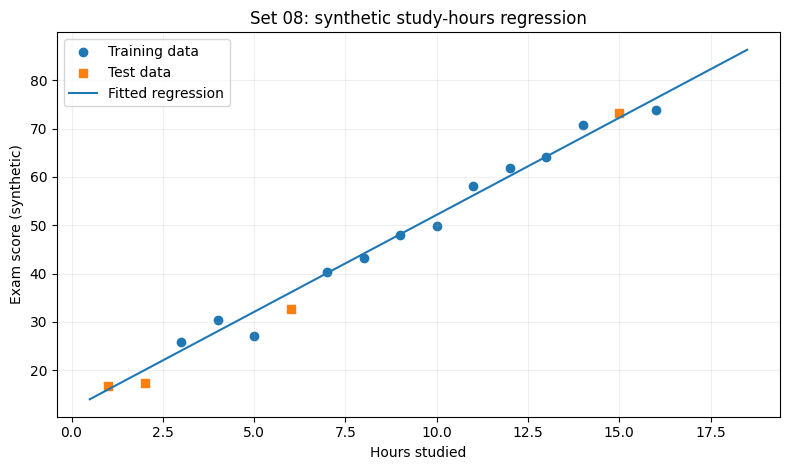

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
# Student practice dataset (synthetic): study hours -> exam score.
# Explicitly illustrative, NOT student survey/observed exam results.
hours=np.arange(1,17,dtype=float)
rng=np.random.default_rng(42)
scores=12+4.0*hours+rng.normal(0,2.5,size=hours.size)
X=hours.reshape(-1,1)
X_train,X_test,y_train,y_test=train_test_split(X,scores,test_size=.25,random_state=42)
model=LinearRegression().fit(X_train,y_train)
print('Samples:',len(hours),'| Train:',len(y_train),'| Test:',len(y_test))
print(f'Slope={model.coef_[0]:.4f}, intercept={model.intercept_:.4f}')
print(f'Train R²={r2_score(y_train,model.predict(X_train)):.4f}')
print(f'Test  R²={r2_score(y_test,model.predict(X_test)):.4f}')
for unseen in [7.5,18.0]:
    print(f'Prediction for {unseen} study hours: {model.predict([[unseen]])[0]:.3f}')
line=np.linspace(0.5,18.5,120).reshape(-1,1)
plt.figure(figsize=(8,4.8))
plt.scatter(X_train[:,0],y_train,label='Training data')
plt.scatter(X_test[:,0],y_test,marker='s',label='Test data')
plt.plot(line[:,0],model.predict(line),label='Fitted regression')
plt.xlabel('Hours studied');plt.ylabel('Exam score (synthetic)')
plt.title('Set 08: synthetic study-hours regression')
plt.grid(alpha=.2);plt.legend();plt.tight_layout();plt.show()


### Result interpretation and discussion
The data intentionally contain random variation and are **synthetic teaching examples**. Test $R^2$ assesses prediction on held-out data but has high sampling variance with only four test cases. A prediction at 18 hours extrapolates beyond the observed range (1–16), so its reliability is weaker than interpolation within the training range. No causal claim is justified.

---
## Q4. Viva voce (10 marks)

| Question | Concise answer |
|:--|:--|
| Depth cutoff? | A search boundary that may hide deeper goals. |
| Why IDDFS repeats root? | Because each larger depth limit starts a new DFS. |
| Cross-validation? | Repeated train/evaluate cycles on different held-out folds. |
| What is data leakage? | Using test/validation information while training or preprocessing. |
| What is standardization? | Subtract training mean and divide by training standard deviation. |
| Train versus test R²? | In-sample fit versus fit on held-out observations. |
| What is extrapolation? | Predicting beyond the range of available training inputs. |

| What is the difference between normalization and standardization? | Min-max normalization usually rescales to a range such as 0 to 1; standardization subtracts the mean and divides by standard deviation. |
| Why should preprocessing be fit within each training fold? | Fitting preprocessing on all data can leak information into cross-validation estimates. |

**Review tip:** Explain the code by identifying the inputs, data structures, stopping conditions, evaluation metrics, and one limitation for each task.

---
### Submission checklist
- [ ] Execute every Python cell in sequence; check the saved output is current.
- [ ] Explain the main formula, trace, and interpretation for Q1, Q2, Q3.
- [ ] Record the original task settings, dataset, random seed, and actual test metrics.
- [ ] For WEKA tasks, run WEKA locally and attach the real result-buffer output/screenshot; notebook instructions **do not substitute for WEKA evidence**.
- [ ] Be ready to discuss one methodological limitation in viva.

**Integrity note:** Code and explanations are independently written for this study repository. Numeric results are calculated from the shown code and may vary with library versions where numerical or tie-breaking differences occur.